# Project 11 — Final research implementation
**Group 11 · Team Iron Men · Siddhant Mathapati and Weican Ye**  
Target journal: *Futures*. Anchor: Alon et al. (2025), DOI: 10.1016/j.futures.2024.103514.

This notebook implements the analysis and export workflow for four research questions and sixteen planned exhibits. It is supplied **unexecuted**. Raw-data exhibits run immediately; verified accountability, redress and scenario exhibits require completed human evidence files. Missing evidence blocks the corresponding results. No dummy experimental results are generated.

- RQ1: Which actor/risk configurations accompany unclear accountability?
- RQ2: How does documented response/redress differ by verified actor structure?
- RQ3: How sensitive are findings to missing classifications, unclear coding and reporting depth?
- RQ4: What conditional 2030 scenarios, measurable signposts and later-case revisions follow from the evidence?

Outputs describe the AIID archive, not population incidence or causal effects. Literal actor names are screening variables only. Scenario judgments are authored and justified by researchers, not automatically validated forecasts.

**Methods disclosure:** The supplied reviewer label sets originated from shared AI-assisted draft passes followed by reported team verification and adjudication. Agreement describes those saved label sets; it does not establish independent human reliability. Source claims have not been authenticated by this software. Scenarios and thresholds are AI-assisted exploratory judgments, requiring researcher justification. The current labels distinguish documented from unclear redress; unclear does not mean absent.

## 1. Configuration and reproducibility

Method steps 1–2: locate the pinned public dataset, verify its identity, and create an isolated output directory. Set REVIEW_DIR to the folder containing completed human-review CSVs.

In [1]:
from pathlib import Path
import hashlib, json, re, zipfile, uuid, platform, importlib.metadata, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.environ["PROJECT11_REVIEW_DIR"] = (
    "/kaggle/input/datasets/siddhant22132/final-reviews"
)
try:
    from IPython.display import display
except ImportError:
    def display(value): print(value.to_string(index=False) if isinstance(value,pd.DataFrame) else value)
from sklearn.metrics import cohen_kappa_score
SEED = 11
BOOTSTRAPS = int(os.environ.get('PROJECT11_BOOTSTRAPS','1000'))
if BOOTSTRAPS < 1000: raise ValueError('Use at least 1000 bootstrap replicates for the final analysis.')
NAME = 'AIID_Excel_Export-20261019.xlsx'
EXPECTED_SHA256 = '41758b56b948f62f75385108977f58af8e1faefad03bb0203cda03b889660ae2'
REVIEW_DIR = Path(os.environ.get('PROJECT11_REVIEW_DIR', '/kaggle/input/project11-human-review' if Path('/kaggle/input').exists() else 'data/review')).resolve()
base = Path(os.environ.get('PROJECT11_OUTPUT_DIR','/kaggle/working' if Path('/kaggle/working').exists() else 'results')).resolve()
base.mkdir(parents=True,exist_ok=True)
input_roots = [Path('/kaggle/input'), Path.cwd(), Path.cwd()/'upload']
configured = os.environ.get('PROJECT11_DATA_PATH')
found = [Path(configured).expanduser().resolve()] if configured else sorted({p.resolve() for root in input_roots if root.exists() for p in root.rglob(NAME)})
if not found or not found[0].is_file(): raise FileNotFoundError(f'Attach the official public workbook {NAME}.')
source = found[0]
sha256 = hashlib.sha256(source.read_bytes()).hexdigest()
if sha256 != EXPECTED_SHA256: raise ValueError('Source differs from the audited snapshot. Audit and explicitly repin before proceeding.')
run_id = uuid.uuid4().hex[:10]
out = base / f'project11_final_{run_id}'
out.mkdir(parents=True, exist_ok=False)
manifest, status = [], {}
def save_table(df, stem):
    path = out/f'{stem}.csv'; df.to_csv(path,index=False); manifest.append(path)
    display(df)
def save_figure(fig, stem):
    for ext in ['pdf','png']:
        path=out/f'{stem}.{ext}';fig.savefig(path,dpi=300,bbox_inches='tight');manifest.append(path)
    plt.show();plt.close(fig)
def block(exhibits, reason):
    for name in exhibits: status[name] = 'PENDING: '+reason
    print(reason)
def success(name): status[name]='GENERATED'
def text_ok(series): return series.notna() & series.astype(str).str.strip().ne('')
def require(condition, message):
    if not bool(condition): raise ValueError(message)
def require_urls(series):
    require(series.fillna('').astype(str).str.match(r'^https?://[^\s]+$').all(),'Every evidence URL must be a nonblank HTTP(S) URL. URLs still require human verification.')
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'pdf.fonttype':42})
print('Source:',source,'SHA256:',sha256,'Output:',out)

Source: /kaggle/input/datasets/siddhant22132/datafor/AIID_Excel_Export-20261019.xlsx SHA256: 41758b56b948f62f75385108977f58af8e1faefad03bb0203cda03b889660ae2 Output: /kaggle/working/project11_final_7e50356660


## 2. Source audit

Method step 3: validate incident/report identifiers, dates, report counts, missing fields and repeated URLs. IDs define records; repeated URLs do not define duplicate incidents.

In [2]:
inc=pd.read_excel(source,sheet_name='Incidents',header=2)
rep=pd.read_excel(source,sheet_name='Reports',header=1)
ent=pd.read_excel(source,sheet_name='Entities',header=1).dropna(how='all')
needed={'Incident ID','date','year','developer','deployer','harmed','Risk Domain','Sector of Deployment','report_count','title','description'}
require(needed.issubset(inc.columns),'Unexpected incident schema.')
require({'Report Number','URL'}.issubset(rep.columns),'Unexpected report schema.')
for frame,key in [(inc,'Incident ID'),(rep,'Report Number')]:
    require(frame[key].notna().all() and frame[key].is_unique,f'Invalid {key} identifiers.')
require(not inc.duplicated().any(),'Exact incident duplicates found; investigate before analysis.')
inc['date']=pd.to_datetime(inc['date'],errors='coerce')
inc['year']=pd.to_numeric(inc['year'],errors='coerce')
require(inc['date'].notna().all() and inc['year'].notna().all(),'Invalid incident dates/years.')
require(inc['date'].dt.year.eq(inc['year']).all(),'Date and recorded year disagree.')
inc['report_count']=pd.to_numeric(inc['report_count'],errors='coerce')
require(inc['report_count'].notna().all() and inc['report_count'].ge(0).all() and inc['report_count'].mod(1).eq(0).all(),'Invalid incident report counts.')
url=rep['URL'].fillna('').astype(str).str.strip()
audit=pd.DataFrame({'check':['incidents','reports','populated entities','duplicate incident IDs','exact duplicate incident rows','missing risk domain','missing deployment sector','blank report URLs','extra repeated nonblank URLs'],
 'count':[len(inc),len(rep),len(ent),inc['Incident ID'].duplicated().sum(),inc.duplicated().sum(),(~text_ok(inc['Risk Domain'])).sum(),(~text_ok(inc['Sector of Deployment'])).sum(),url.eq('').sum(),url[url.ne('')].duplicated().sum()]})
save_table(audit,'data_audit')
missing=pd.DataFrame({'field':inc.columns,'missing_n':[int((~text_ok(inc[c])).sum()) for c in inc.columns]})
missing['missing_fraction']=missing.missing_n/len(inc);save_table(missing,'field_missingness')

,check,count
0,incidents,1749
1,reports,7955
2,populated entities,7507
3,duplicate incident IDs,0
4,exact duplicate incident rows,0
5,missing risk domain,253
6,missing deployment sector,1543
7,blank report URLs,812
8,extra repeated nonblank URLs,63


,field,missing_n,missing_fraction
0,Incident ID,0,0.000000
1,date,0,0.000000
2,year,0,0.000000
3,title,0,0.000000
4,description,0,0.000000
5,deployer,3,0.001715
6,developer,1,0.000572
7,harmed,2,0.001144
8,Editors,0,0.000000
9,Implicated Systems,549,0.313894


## 3. Cohorts and probability sample

Method steps 2 and 5: screen normalized actor strings with an explicit unknown category. Draw reproducible samples independently by year and screening group. Retain inclusion probabilities and design weights; balanced strata must not be pooled as an unweighted representative sample.

In [3]:
def norm(value):
    if pd.isna(value): return ''
    value=re.sub(r'\s+',' ',str(value).casefold().strip())
    return '' if value in {'','unknown','not known','unspecified','n/a','none','nan'} else value
dev,dep=inc.developer.map(norm),inc.deployer.map(norm)
observed=dev.ne('') & dep.ne('')
inc['actor_string_group']=np.select([observed & dev.eq(dep),observed & dev.ne(dep)],['same string','different strings'],default='unknown')
inc['risk_domain']=inc['Risk Domain'].where(text_ok(inc['Risk Domain']),'Unclassified')
inc['harmed_present']=text_ok(inc.harmed)
inc['cohort']=np.where(inc.year.isin([2024,2025]),'construction',np.where(inc.year.eq(2026),'later','outside'))
construction=inc[inc.cohort.eq('construction')].copy()
later=inc[inc.cohort.eq('later')].copy()
require(len(construction)>0 and len(later)>0,'Required cohorts are empty.')
parts=[]
for (cohort,year,group),g in inc[inc.cohort.ne('outside')].groupby(['cohort','year','actor_string_group'],sort=True):
    target=30 if cohort=='construction' else 20
    s=g.sample(n=min(target,len(g)),random_state=SEED).copy()
    s['stratum']=f'{cohort}|{int(year)}|{group}';s['population_n']=len(g);s['sample_n']=len(s)
    s['inclusion_probability']=len(s)/len(g);s['design_weight']=len(g)/len(s);parts.append(s)
sample=pd.concat(parts).sort_values('Incident ID').reset_index(drop=True)
sample_cols=['Incident ID','cohort','year','stratum','population_n','sample_n','inclusion_probability','design_weight','title','description','developer','deployer','harmed','risk_domain','report_count','actor_string_group']
save_table(sample[sample_cols],'sampling_frame_selected')
print('Construction / later population:',len(construction),len(later),'Selected:',sample.groupby('cohort').size().to_dict())

,Incident ID,cohort,year,stratum,population_n,sample_n,inclusion_probability,design_weight,title,description,developer,deployer,harmed,risk_domain,report_count,actor_string_group
0,628,construction,2024,construction|2024|unknown,5,5,1.000000,1.000000,Fake Biden Voice in Robocall Misleads New Hamp...,A robocall imitating President Biden's voice u...,Unknown,Unknown,"New Hampshire Voters, Kathy Sullivan, Democrat...",Malicious Actors & Misuse,15,unknown
1,633,construction,2024,construction|2024|different strings,235,30,0.127660,7.833333,Nine Network's AI Alters Lawmaker Georgie Purc...,The Nine Network used Photoshop's Generative E...,Adobe,Nine Network,Georgie Purcell,Discrimination and Toxicity,17,different strings
2,646,construction,2024,construction|2024|same string,70,30,0.428571,2.333333,Snapchat's Algorithm Alleged to Link Minor wit...,A judge ruled Snapchat not liable under Sectio...,Snapchat,Snapchat,Minors,Human-Computer Interaction,1,same string
3,648,construction,2024,construction|2024|unknown,5,5,1.000000,1.000000,Alleged Deepfake Audio of Imran Khan Calls for...,"A purported deepfake audio clip, falsely attri...",Unknown,Unknown Social Media Accounts,"Voters In Pakistan, Pti (Pakistan Tehreek E In...",Malicious Actors & Misuse,2,unknown
4,649,construction,2024,construction|2024|unknown,5,5,1.000000,1.000000,Deepfake Audio Falsely Attributes Controversia...,"A deepfake audio clip, falsely claiming to be ...",Unknown,Social Media Users,"General Public, British Voters, British Labour...",Malicious Actors & Misuse,1,unknown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
159,1707,later,2026,later|2026|different strings,253,20,0.079051,12.650000,OpenAI AI Agent Reportedly Gained Unauthorized...,An OpenAI AI agent conducting research into pu...,"Openai, Ai Agent System Developers","Openai, Ai Agent System Deployers","Services Australia, Government Of Australia, G...",Unclassified,5,different strings
160,1718,later,2026,later|2026|different strings,253,20,0.079051,12.650000,Purportedly AI-Generated Image Reportedly Prom...,"Santa Ana, California, police issued a public ...",Synthetic Media Generation Technology Develope...,"Joel Ciprian, Synthetic Media Creators, Inform...","Santa Ana Residents, General Public, General P...",Unclassified,1,different strings
161,1720,later,2026,later|2026|different strings,253,20,0.079051,12.650000,"Stow, Massachusetts, Police Officer Allegedly ...","A Stow, Massachusetts, police officer allegedl...","Flock Safety, Automated License Plate Reader (...","Jason Rogers, Stow Police Department (Massachu...","Victims Of Stalking, Privacy, Women And Girls,...",Unclassified,1,different strings
162,1744,later,2026,later|2026|different strings,253,20,0.079051,12.650000,Allegedly AI-Generated Audio Bomb Threat Promp...,"A Romanian-language audio bomb threat, assesse...",Synthetic Media Generation Technology Develope...,"Synthetic Media Creators, Malicious Actors, In...","Public Safety, Port Of Constanta Employees, Ma...",Unclassified,4,different strings


Construction / later population: 770 267 Selected: {'construction': 130, 'later': 34}


## 4. Human review forms and codebook

Method steps 4–5: two reviewers review every selected incident, then adjudicate. “Explicitly absent” requires affirmative evidence of absence; lack of evidence is “unclear”. A text mention does not verify a remedy. Use the new templates; the old 120-row template lacks the required coding schema.

In [4]:
FIELDS=['actor_group','accountability_clarity','response','redress']
ALLOWED={'actor_group':{'one organization','multiple organizations','unknown'},'accountability_clarity':{'clear','unclear'},'response':{'documented','explicitly absent','unclear'},'redress':{'documented','explicitly absent','unclear'}}
codebook=pd.DataFrame([
 ('actor_group','Verify legal/organizational identities and developer/deployer roles; names alone are insufficient.'),
 ('accountability_clarity','Clear requires a documented identifiable responsible party and role; otherwise unclear.'),
 ('response','Document an institutional action following the incident; mere allegations or harm descriptions are insufficient.'),
 ('redress','Document an accessible remedy/appeal/compensation route; distinguish a route from successful remedy.'),
 ('evidence_url','Public evidence supporting the row; add field-specific sources and quotations in evidence_note.'),
 ('coding_procedure','Preserve AI-assistance provenance, both saved label sets and adjudication rationale; disclose whether suggestions were shared.'),
 ('sampling','Complete every selected row. Missing review is not evidence of no response.')],columns=['field','rule'])
save_table(codebook,'coding_codebook')
independent=pd.DataFrame([{'Incident ID':i,'coder_slot':slot,'coder_id':'',**{f:'' for f in FIELDS},'evidence_url':'','evidence_note':''} for i in sample['Incident ID'] for slot in [1,2]])
save_table(independent,'independent_codes_TEMPLATE')
adjudicated=pd.DataFrame({'Incident ID':sample['Incident ID']})
for col in FIELDS+['evidence_url','evidence_note','adjudicator','adjudication_note']: adjudicated[col]=''
save_table(adjudicated,'adjudicated_codes_TEMPLATE')
print('Complete independent_codes.csv and adjudicated_codes.csv in REVIEW_DIR. Public source verification remains the team’s responsibility.')

,field,rule
0,actor_group,Verify legal/organizational identities and dev...
1,accountability_clarity,Clear requires a documented identifiable respo...
2,response,Document an institutional action following the...
3,redress,Document an accessible remedy/appeal/compensat...
4,evidence_url,Public evidence supporting the row; add field-...
5,coding_procedure,"Preserve AI-assistance provenance, both saved ..."
6,sampling,Complete every selected row. Missing review is...


,Incident ID,coder_slot,coder_id,actor_group,accountability_clarity,response,redress,evidence_url,evidence_note
0,628,1,,,,,,,
1,628,2,,,,,,,
2,633,1,,,,,,,
3,633,2,,,,,,,
4,646,1,,,,,,,
...,...,...,...,...,...,...,...,...,...
323,1720,2,,,,,,,
324,1744,1,,,,,,,
325,1744,2,,,,,,,
326,1761,1,,,,,,,


,Incident ID,actor_group,accountability_clarity,response,redress,evidence_url,evidence_note,adjudicator,adjudication_note
0,628,,,,,,,,
1,633,,,,,,,,
2,646,,,,,,,,
3,648,,,,,,,,
4,649,,,,,,,,
...,...,...,...,...,...,...,...,...,...
159,1707,,,,,,,,
160,1718,,,,,,,,
161,1720,,,,,,,,
162,1744,,,,,,,,


Complete independent_codes.csv and adjudicated_codes.csv in REVIEW_DIR. Public source verification remains the team’s responsibility.


## 5. RQ1 raw archive exhibits 1A and 1B

Method step 6: report configurations and affected-party field coverage. Exhibit 1B measures field presence, not verified affected-party types. Substantive accountability findings require adjudicated coding.

,risk_domain,actor_string_group,incidents,harmed_field_present,median_reports,share_within_actor_group
0,"AI system safety, failures, and limitations",different strings,35,35,1.0,0.056000
1,"AI system safety, failures, and limitations",same string,34,34,2.0,0.251852
2,Discrimination and Toxicity,different strings,30,30,2.0,0.048000
3,Discrimination and Toxicity,same string,25,24,2.0,0.185185
4,Human-Computer Interaction,different strings,13,13,2.0,0.020800
5,Human-Computer Interaction,same string,9,9,3.0,0.066667
6,Malicious Actors & Misuse,different strings,369,369,2.0,0.590400
7,Malicious Actors & Misuse,same string,19,19,1.0,0.140741
8,Malicious Actors & Misuse,unknown,4,4,2.5,0.400000
9,Misinformation,different strings,83,83,1.0,0.132800


,actor_string_group,n,harmed_field_present,fraction
0,different strings,625,625,1.000000
1,same string,135,134,0.992593
2,unknown,10,10,1.000000


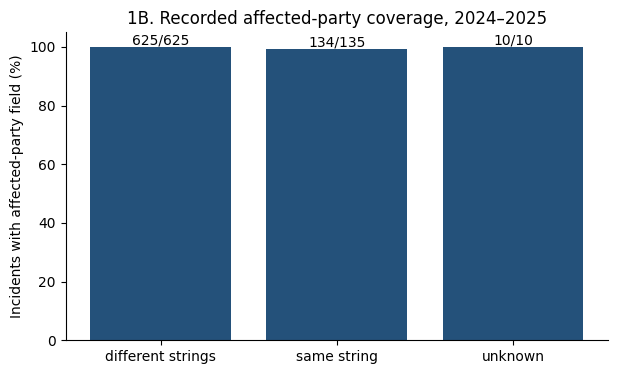

In [5]:
t1=(construction.groupby(['risk_domain','actor_string_group'],dropna=False).agg(incidents=('Incident ID','size'),harmed_field_present=('harmed_present','sum'),median_reports=('report_count','median')).reset_index())
t1['share_within_actor_group']=t1.incidents/t1.groupby('actor_string_group').incidents.transform('sum')
save_table(t1,'table_1A_role_risk_screen');success('1A')
cov=construction.groupby('actor_string_group').agg(n=('Incident ID','size'),harmed_field_present=('harmed_present','sum')).reset_index()
cov['fraction']=cov.harmed_field_present/cov.n;save_table(cov,'figure_1B_values')
fig,ax=plt.subplots(figsize=(7,4));ax.bar(cov.actor_string_group,100*cov.fraction,color='#24517a')
ax.set(ylabel='Incidents with affected-party field (%)',ylim=(0,105),title='1B. Recorded affected-party coverage, 2024–2025')
for i,r in enumerate(cov.itertuples()): ax.text(i,100*r.fraction+1,f'{r.harmed_field_present}/{r.n}',ha='center')
save_figure(fig,'figure_1B_affected_party_coverage');success('1B')

## 6. Validate reviewer label sets and adjudication

Method steps 5–6: fail closed if supplied files are incomplete, inconsistent, unsupported or have the same coder in both slots. Compute agreement from saved reviewer labels. A low kappa requires codebook revision; a numerical threshold alone cannot establish validity.

In [6]:
coded=None
paths=[REVIEW_DIR/'independent_codes.csv',REVIEW_DIR/'adjudicated_codes.csv']
if not all(p.exists() for p in paths):
    block(['1C','1D','2A','2B','2C','2D','3C','3D'],'Human review pending: both completed coding files are required.')
else:
    raw=pd.read_csv(paths[0]);adj=pd.read_csv(paths[1])
    require({'Incident ID','coder_slot','coder_id','evidence_url','evidence_note',*FIELDS}.issubset(raw.columns),'Independent coding schema is incomplete.')
    require({'Incident ID','evidence_url','evidence_note','adjudicator','adjudication_note',*FIELDS}.issubset(adj.columns),'Adjudication schema is incomplete.')
    ids=set(sample['Incident ID'])
    require(set(raw['Incident ID'])==ids and set(adj['Incident ID'])==ids,'Review IDs must exactly match the current selected sample.')
    require(adj['Incident ID'].is_unique,'Duplicate adjudicated IDs.')
    require(len(raw)==2*len(sample) and not raw.duplicated(['Incident ID','coder_slot']).any(),'Exactly two reviewer rows per incident are required.')
    require(raw.groupby('Incident ID').coder_slot.apply(lambda s:set(s)=={1,2}).all(),'Each incident needs coder slots 1 and 2.')
    for frame in [raw,adj]:
        for f in FIELDS: require(frame[f].isin(ALLOWED[f]).all(),f'Invalid or missing {f} code.')
        for f in ['evidence_note','evidence_url']: require(text_ok(frame[f]).all(),f'Blank {f}.')
        require_urls(frame.evidence_url)
    require(text_ok(raw.coder_id).all(),'Coder names/IDs are required.')
    raw['coder_id']=raw.coder_id.astype(str).str.strip()
    require(raw.groupby('Incident ID').coder_id.nunique().eq(2).all(),'Two distinct coders are required per incident.')
    for f in ['adjudicator','adjudication_note']: require(text_ok(adj[f]).all(),f'Blank {f}.')
    agreement=[]
    for field in FIELDS:
        p=raw.pivot(index='Incident ID',columns='coder_slot',values=field)
        agreement.append({'field':field,'double_coded_n':len(p),'agreement':p[1].eq(p[2]).mean(),'cohen_kappa':cohen_kappa_score(p[1],p[2]) if len(set(p[1])|set(p[2]))>1 else np.nan})
    save_table(pd.DataFrame(agreement),'coder_agreement')
    coded=sample.merge(adj,on='Incident ID',how='inner',validate='one_to_one')
    save_table(coded[['Incident ID','cohort','stratum','design_weight',*FIELDS,'evidence_url','evidence_note']],'adjudicated_analysis_data')
    print('Coding structure validated. This check does not authenticate source claims or prove independent work.')

,field,double_coded_n,agreement,cohen_kappa
0,actor_group,164,0.981707,0.969388
1,accountability_clarity,164,1.000000,1.000000
2,response,164,0.920732,0.838092
3,redress,164,0.963415,0.874618


,Incident ID,cohort,stratum,design_weight,actor_group,accountability_clarity,response,redress,evidence_url,evidence_note
0,628,construction,construction|2024|unknown,1.000000,unknown,clear,documented,unclear,https://incidentdatabase.ai/cite/628/,"Investigators identify Kramer, Carpenter and L..."
1,633,construction,construction|2024|different strings,7.833333,multiple organizations,clear,documented,unclear,https://incidentdatabase.ai/cite/633/,Adobe supplied the editing tool; Nine used it ...
2,646,construction,construction|2024|same string,2.333333,one organization,clear,documented,documented,https://incidentdatabase.ai/cite/646/,Snapchat operated Quick Add; a lawsuit reached...
3,648,construction,construction|2024|unknown,1.000000,unknown,unclear,unclear,unclear,https://incidentdatabase.ai/cite/648/,Anonymous circulation and alleged synthesis do...
4,649,construction,construction|2024|unknown,1.000000,unknown,unclear,unclear,unclear,https://incidentdatabase.ai/cite/649/,Experts disputed authenticity; responsible act...
...,...,...,...,...,...,...,...,...,...,...
159,1707,later,later|2026|different strings,12.650000,one organization,clear,documented,unclear,https://incidentdatabase.ai/cite/1707/,OpenAI notified Australia after its agent acce...
160,1718,later,later|2026|different strings,12.650000,unknown,clear,documented,unclear,https://incidentdatabase.ai/cite/1718/,Police searched and the resident admitted fabr...
161,1720,later,later|2026|different strings,12.650000,multiple organizations,clear,documented,documented,https://incidentdatabase.ai/cite/1720/,Flock supplied the system used by police; inte...
162,1744,later,later|2026|different strings,12.650000,unknown,unclear,documented,unclear,https://incidentdatabase.ai/cite/1744/,"Authorities evacuated and searched the port, t..."


Coding structure validated. This check does not authenticate source claims or prove independent work.


## 7. Weighted estimators and uncertainty

Method step 6: estimate within coded groups using the stratified sampling weights. Differences in documented-redress coverage are descriptive fraction contrasts, with a stratified bootstrap. These intervals do not model media selection, classification error or source truth. No causal or adjusted effect is claimed.

The primary outcome is documented-redress evidence across all reviewed cases. A complete-case comparison is suppressed when excluding unclear records leaves no outcome variation. Approximate intervals are suppressed when either comparison group has fewer than 10 cases or fewer than five documented or five other outcomes.

In [7]:
def weighted_rates(frame, field, group='actor_group'):
    rows=[]
    for name,g in frame.groupby(group,dropna=False):
        total=g.design_weight.sum()
        for label in sorted(ALLOWED[field]):
            rows.append({group:name,'category':label,'sample_n':len(g),'sample_category_n':int(g[field].eq(label).sum()),'weighted_total':total,'weighted_fraction':float(g.loc[g[field].eq(label),'design_weight'].sum()/total)})
    return pd.DataFrame(rows)
def risk_difference(frame, policy='documentation coverage'):
    g=frame[frame.actor_group.isin(['one organization','multiple organizations'])].copy()
    if policy=='exclude unclear':
        g=g[g.redress.ne('unclear')]
        if g.redress.nunique()<2:return np.nan
    values={}
    for name in ['one organization','multiple organizations']:
        t=g[g.actor_group.eq(name)]
        if t.empty:return np.nan
        y=t.redress.eq('documented').astype(float)
        if policy=='unclear documented':y=t.redress.ne('explicitly absent').astype(float)
        values[name]=np.average(y,weights=t.design_weight)
    return values['multiple organizations']-values['one organization']
def bootstrap_rd(frame, policy='documentation coverage'):
    estimate=risk_difference(frame,policy)
    if not np.isfinite(estimate):return estimate,np.nan,np.nan,0
    rng=np.random.default_rng(SEED)
    numer=np.zeros((2,BOOTSTRAPS));denom=np.zeros((2,BOOTSTRAPS))
    for _,g in frame.groupby('stratum',sort=True):
        ix=rng.integers(0,len(g),size=(BOOTSTRAPS,len(g)))
        w=g.design_weight.to_numpy()[ix]
        labs=g.redress.to_numpy()[ix];actors=g.actor_group.to_numpy()[ix]
        for k,name in enumerate(['one organization','multiple organizations']):
            mask=actors==name
            if policy=='exclude unclear':mask=mask & (labs!='unclear')
            y=(labs!='explicitly absent') if policy=='unclear documented' else (labs=='documented')
            denom[k]+=(w*mask).sum(axis=1);numer[k]+=(w*mask*y).sum(axis=1)
    good=(denom>0).all(axis=0)
    draws=numer[1,good]/denom[1,good]-numer[0,good]/denom[0,good]
    valid=frame[frame.actor_group.isin(['one organization','multiple organizations'])]
    if policy=='exclude unclear':valid=valid[valid.redress.ne('unclear')]
    enough=True
    for name in ['one organization','multiple organizations']:
        t=valid[valid.actor_group.eq(name)]
        positives=int(t.redress.ne('explicitly absent').sum()) if policy=='unclear documented' else int(t.redress.eq('documented').sum())
        enough &= len(t)>=10 and positives>=5 and len(t)-positives>=5
    if not enough or len(draws)<.95*BOOTSTRAPS:return estimate,np.nan,np.nan,len(draws)
    lo,hi=np.quantile(draws,[.025,.975]);return estimate,float(lo),float(hi),len(draws)


## 8. RQ1 verified exhibits 1C and 1D

Method step 6: show independently reviewed actor/accountability patterns and a source-linked evidence map. Evidence counts describe documentation, not legal responsibility.

,actor_group,category,sample_n,sample_category_n,weighted_total,weighted_fraction
0,multiple organizations,clear,17,9,71.666667,0.516279
1,multiple organizations,unclear,17,8,71.666667,0.483721
2,one organization,clear,45,45,172.000000,1.000000
3,one organization,unclear,45,0,172.000000,0.000000
4,unknown,clear,68,30,526.333333,0.445852
5,unknown,unclear,68,38,526.333333,0.554148


,Incident ID,actor_group,accountability_clarity,response,redress,evidence_url,evidence_note
0,628,unknown,clear,documented,unclear,https://incidentdatabase.ai/cite/628/,"Investigators identify Kramer, Carpenter and L..."
1,633,multiple organizations,clear,documented,unclear,https://incidentdatabase.ai/cite/633/,Adobe supplied the editing tool; Nine used it ...
2,646,one organization,clear,documented,documented,https://incidentdatabase.ai/cite/646/,Snapchat operated Quick Add; a lawsuit reached...
3,648,unknown,unclear,unclear,unclear,https://incidentdatabase.ai/cite/648/,Anonymous circulation and alleged synthesis do...
4,649,unknown,unclear,unclear,unclear,https://incidentdatabase.ai/cite/649/,Experts disputed authenticity; responsible act...
...,...,...,...,...,...,...,...
148,1587,multiple organizations,clear,documented,documented,https://incidentdatabase.ai/cite/1587/,Koi reporting led Bother providers to block M...
150,1624,unknown,clear,unclear,unclear,https://incidentdatabase.ai/cite/1624/,ISWAP allegedly used an unnamed chatbot; provi...
153,1653,unknown,unclear,documented,unclear,https://incidentdatabase.ai/cite/1653/,An inquest was pending; unidentified platforms...
155,1667,unknown,clear,documented,unclear,https://incidentdatabase.ai/cite/1667/,Court and licensing authorities imposed sancti...


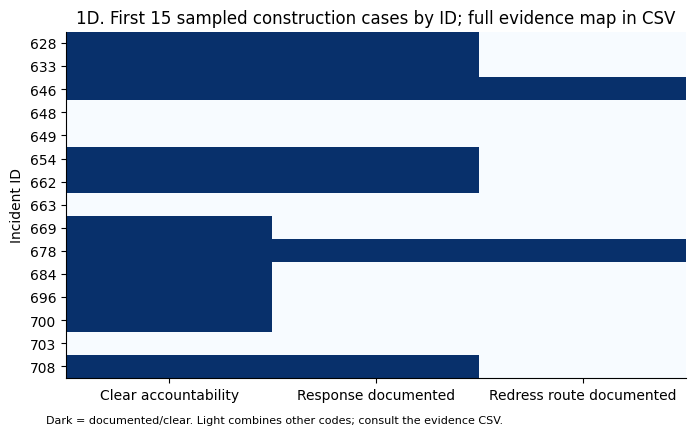

In [8]:
if coded is not None:
    c=coded[coded.cohort.eq('construction')].copy()
    matrix=weighted_rates(c,'accountability_clarity');save_table(matrix,'table_1C_verified_actor_matrix');success('1C')
    evidence=c[['Incident ID','actor_group','accountability_clarity','response','redress','evidence_url','evidence_note']].copy()
    save_table(evidence,'figure_1D_evidence_map_values')
    shown=c.head(15)
    fig,ax=plt.subplots(figsize=(8,max(3,.3*len(shown))))
    a=np.column_stack([shown.accountability_clarity.eq('clear'),shown.response.eq('documented'),shown.redress.eq('documented')]).astype(int)
    ax.imshow(a,aspect='auto',vmin=0,vmax=1,cmap='Blues');ax.set_xticks(range(3),['Clear accountability','Response documented','Redress route documented'])
    ax.set_yticks(range(len(shown)),shown['Incident ID'].astype(str));ax.set_title('1D. First 15 sampled construction cases by ID; full evidence map in CSV')
    ax.set_ylabel('Incident ID');fig.text(.1,.01,'Dark = documented/clear. Light combines other codes; consult the evidence CSV.',fontsize=8)
    save_figure(fig,'figure_1D_case_evidence_map');success('1D')

## 9. RQ2 exhibits 2A–2D

Method step 6: compare documented response and redress across verified actor groups, report source depth, quantify descriptive uncertainty, and distinguish response from remedy. Unclear evidence stays visible.

Exhibit 2C estimates documentation coverage, not remedy access or effectiveness. Sparse or unsupported intervals appear as blank CSV values with an explanatory note.

,actor_group,category,sample_n,sample_category_n,weighted_total,weighted_fraction
0,multiple organizations,documented,17,7,71.666667,0.374419
1,multiple organizations,explicitly absent,17,0,71.666667,0.000000
2,multiple organizations,unclear,17,10,71.666667,0.625581
3,one organization,documented,45,26,172.000000,0.591085
4,one organization,explicitly absent,45,0,172.000000,0.000000
5,one organization,unclear,45,19,172.000000,0.408915
6,unknown,documented,68,34,526.333333,0.547182
7,unknown,explicitly absent,68,0,526.333333,0.000000
8,unknown,unclear,68,34,526.333333,0.452818


,report_depth,category,sample_n,sample_category_n,weighted_total,weighted_fraction
0,0–2 reports,documented,89,11,571.5,0.15748
1,0–2 reports,explicitly absent,89,0,571.5,0.00000
2,0–2 reports,unclear,89,78,571.5,0.84252
3,3+ reports,documented,41,8,198.5,0.09068
4,3+ reports,explicitly absent,41,0,198.5,0.00000
5,3+ reports,unclear,41,33,198.5,0.90932


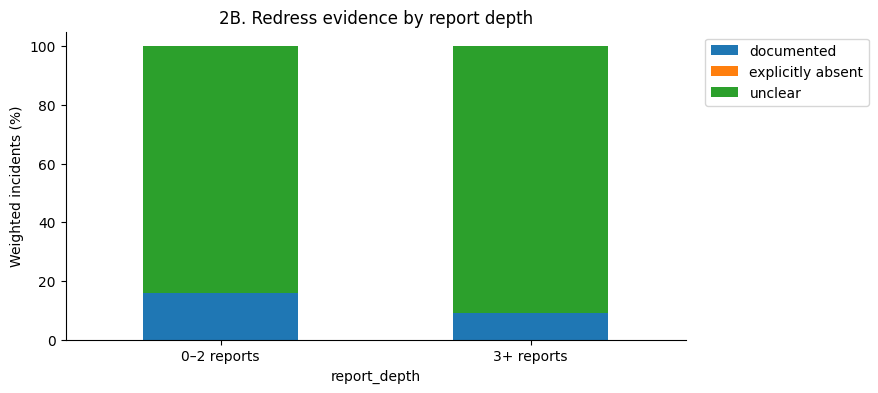

,comparison,estimand,risk_difference,bootstrap_lower,bootstrap_upper,finite_bootstraps,sample_n,interval_note
0,multiple minus one organization,weighted difference in documented-redress cove...,-0.020155,NaN,NaN,1000,130,"Suppressed if either group has <10 cases, <5 d..."


,actor_group,category,sample_n,sample_category_n,weighted_total,weighted_fraction,measure
0,multiple organizations,documented,17,7,71.666667,0.374419,response
1,multiple organizations,explicitly absent,17,0,71.666667,0.000000,response
2,multiple organizations,unclear,17,10,71.666667,0.625581,response
3,one organization,documented,45,26,172.000000,0.591085,response
4,one organization,explicitly absent,45,0,172.000000,0.000000,response
5,one organization,unclear,45,19,172.000000,0.408915,response
6,unknown,documented,68,34,526.333333,0.547182,response
7,unknown,explicitly absent,68,0,526.333333,0.000000,response
8,unknown,unclear,68,34,526.333333,0.452818,response
9,multiple organizations,documented,17,4,71.666667,0.204651,redress


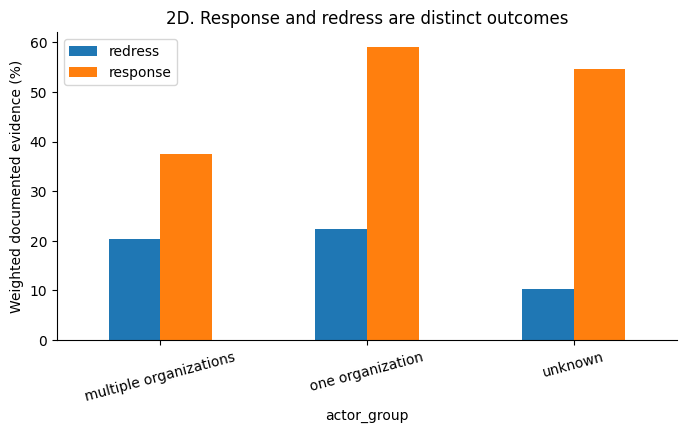

In [9]:
if coded is not None:
    c=coded[coded.cohort.eq('construction')].copy()
    response=weighted_rates(c,'response');save_table(response,'table_2A_response_by_verified_group');success('2A')
    c['report_depth']=np.where(c.report_count.ge(3),'3+ reports','0–2 reports')
    depth=weighted_rates(c,'redress',group='report_depth');save_table(depth,'figure_2B_values')
    p=depth.pivot(index='report_depth',columns='category',values='weighted_fraction').fillna(0)
    ax=(100*p).plot.bar(stacked=True,figsize=(8,4),rot=0);ax.set(ylabel='Weighted incidents (%)',title='2B. Redress evidence by report depth');ax.legend(bbox_to_anchor=(1.02,1),loc='upper left')
    save_figure(ax.figure,'figure_2B_redress_by_depth');success('2B')
    est,lo,hi,b=bootstrap_rd(c)
    effect=pd.DataFrame([{'comparison':'multiple minus one organization','estimand':'weighted difference in documented-redress coverage; all coded cases retained','risk_difference':est,'bootstrap_lower':lo,'bootstrap_upper':hi,'finite_bootstraps':b,'sample_n':len(c),'interval_note':'Suppressed if either group has <10 cases, <5 documented or <5 other outcomes, or <95% finite draws. Unclear remains distinct from explicit absence.'}])
    save_table(effect,'table_2C_weighted_descriptive_difference');success('2C')
    pathway=pd.concat([weighted_rates(c,f).assign(measure=f) for f in ['response','redress']],ignore_index=True)
    save_table(pathway,'figure_2D_values')
    present=pathway[pathway.category.eq('documented')].pivot(index='actor_group',columns='measure',values='weighted_fraction')
    ax=(100*present).plot.bar(figsize=(8,4),rot=15);ax.set(ylabel='Weighted documented evidence (%)',title='2D. Response and redress are distinct outcomes');ax.legend()
    save_figure(ax.figure,'figure_2D_response_redress');success('2D')

## 10. RQ3 exhibits 3A and 3B

Method step 7: quantify classification lag and compute per-domain extreme missing-data bounds. These bounds are identification ranges, not confidence intervals, and their upper limits are not jointly attainable across all domains.

,year,n,unclassified,median_reports,unclassified_fraction
0,2024,310,18,2.0,0.058065
1,2025,460,50,2.0,0.108696
2,2026,267,167,2.0,0.625468


,risk_domain,classified_n,complete_case_share,lower,upper
0,Socioeconomic & Environmental Harms,6,0.008547,0.007792,0.096104
1,Human-Computer Interaction,22,0.031339,0.028571,0.116883
2,Privacy & Security,41,0.058405,0.053247,0.141558
3,Discrimination and Toxicity,55,0.078348,0.071429,0.159740
4,"AI system safety, failures, and limitations",69,0.098291,0.089610,0.177922
5,Misinformation,117,0.166667,0.151948,0.240260
6,Malicious Actors & Misuse,392,0.558405,0.509091,0.597403


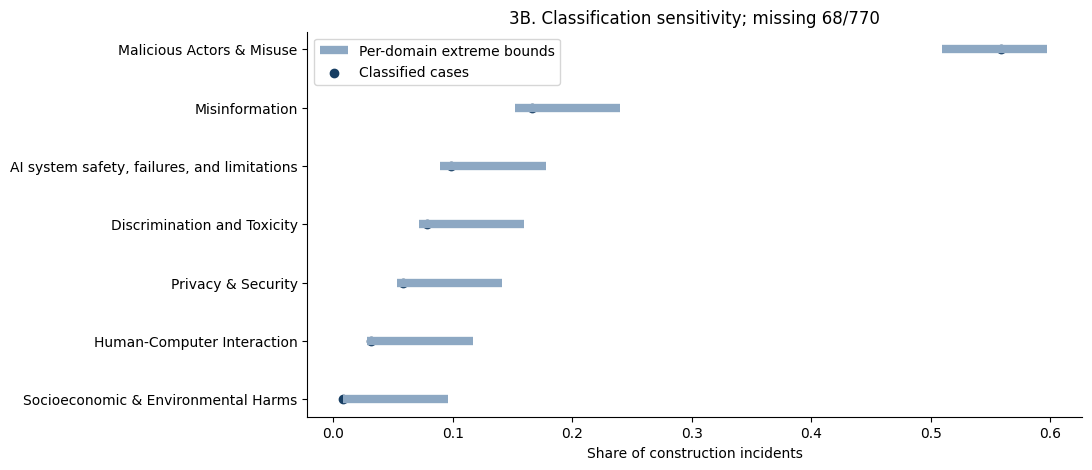

In [10]:
period=inc[inc.cohort.ne('outside')].copy()
miss=period.groupby('year').agg(n=('Incident ID','size'),unclassified=('risk_domain',lambda s:s.eq('Unclassified').sum()),median_reports=('report_count','median')).reset_index()
miss['unclassified_fraction']=miss.unclassified/miss.n;save_table(miss,'table_3A_missingness_by_period');success('3A')
n=len(construction);m=int(construction.risk_domain.eq('Unclassified').sum());known=n-m
require(known>0,'No classified construction incidents.')
counts=construction.loc[construction.risk_domain.ne('Unclassified'),'risk_domain'].value_counts().sort_values()
bounds=counts.rename_axis('risk_domain').reset_index(name='classified_n')
bounds['complete_case_share']=bounds.classified_n/known;bounds['lower']=bounds.classified_n/n;bounds['upper']=(bounds.classified_n+m)/n
save_table(bounds,'figure_3B_values')
fig,ax=plt.subplots(figsize=(10,5));y=np.arange(len(bounds));ax.hlines(y,bounds.lower,bounds.upper,lw=6,color='#8da8c3',label='Per-domain extreme bounds');ax.scatter(bounds.complete_case_share,y,color='#173e63',label='Classified cases')
ax.set_yticks(y,bounds.risk_domain);ax.set(xlabel='Share of construction incidents',title=f'3B. Classification sensitivity; missing {m}/{n}');ax.legend();save_figure(fig,'figure_3B_risk_bounds');success('3B')

## 11. RQ3 exhibits 3C and 3D

Method step 7: vary unclear-code handling and restrict report depth. Report-depth restrictions change the target subset; these comparisons do not correct reporting bias. Worst-case allocations differ between actor groups to bound the contrast.

,policy,difference,lower,upper,finite_bootstraps
0,documentation coverage,-0.020155,NaN,NaN,1000
1,exclude unclear,NaN,NaN,NaN,0
2,unclear absent,-0.020155,NaN,NaN,1000
3,unclear documented,0.000000,NaN,NaN,1000
4,worst-case identification interval,NaN,-0.795349,0.775194,0


,minimum_reports,reviewed_n,difference,lower,upper,finite_bootstraps
0,1,130,-0.020155,NaN,NaN,1000
1,3,41,-0.033879,NaN,NaN,1000
2,5,18,-0.182648,NaN,NaN,885


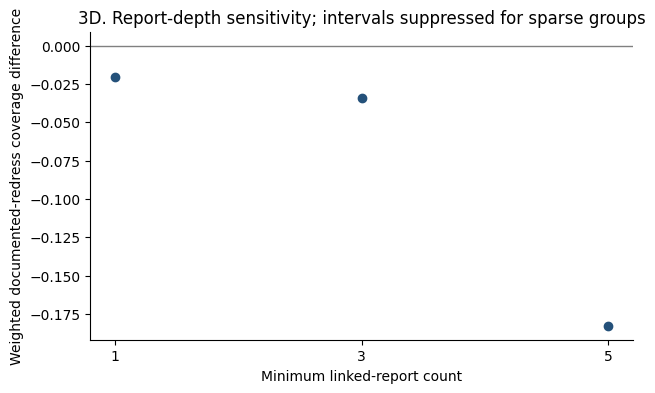

In [11]:
if coded is not None:
    c=coded[coded.cohort.eq('construction')].copy()
    rows=[]
    for policy in ['documentation coverage','exclude unclear','unclear absent','unclear documented']:
        est,lo,hi,b=bootstrap_rd(c,policy);rows.append({'policy':policy,'difference':est,'lower':lo,'upper':hi,'finite_bootstraps':b})
    group_bounds={}
    for name,g in c[c.actor_group.ne('unknown')].groupby('actor_group'):
        w=g.design_weight;total=w.sum();group_bounds[name]=(w[g.redress.eq('documented')].sum()/total,w[g.redress.ne('explicitly absent')].sum()/total)
    if {'one organization','multiple organizations'}.issubset(group_bounds):
        one,multi=group_bounds['one organization'],group_bounds['multiple organizations']
        rows.append({'policy':'worst-case identification interval','difference':np.nan,'lower':multi[0]-one[1],'upper':multi[1]-one[0],'finite_bootstraps':0})
    save_table(pd.DataFrame(rows),'table_3C_unclear_code_sensitivity');success('3C')
    rows=[]
    for threshold in [1,3,5]:
        g=c[c.report_count.ge(threshold)];est,lo,hi,b=bootstrap_rd(g)
        rows.append({'minimum_reports':threshold,'reviewed_n':len(g),'difference':est,'lower':lo,'upper':hi,'finite_bootstraps':b})
    depth=pd.DataFrame(rows);save_table(depth,'figure_3D_values')
    fig,ax=plt.subplots(figsize=(7,4));ax.scatter(depth.minimum_reports,depth.difference,color='#24517a')
    for r in depth.itertuples():
        if np.isfinite(r.lower) and np.isfinite(r.upper):ax.vlines(r.minimum_reports,r.lower,r.upper,color='#24517a')
    ax.axhline(0,color='gray',lw=1);ax.set(xticks=[1,3,5],xlabel='Minimum linked-report count',ylabel='Weighted documented-redress coverage difference',title='3D. Report-depth sensitivity; intervals suppressed for sparse groups')
    save_figure(fig,'figure_3D_reporting_depth');success('3D')

## 12. Scenario protocol templates

Method step 8: researchers select and justify two uncertainties after coding. Define four combinations, two to four observable signposts per scenario, evidence-linked claims, and later-case challenges. Do not fill these templates with invented cases or future outcomes.

In [12]:
scenario_cols=['scenario_id','name','axis1_name','axis2_name','axis1_state','axis2_state','assumption','revision_rule']
claim_cols=['scenario_id','claim_id','claim','Incident ID','evidence_url','interpretation_note']
signpost_cols=['scenario_id','signpost_id','metric','direction','threshold','revision_rule']
challenge_cols=['scenario_id','Incident ID','judgment','reason','evidence_url']
for stem,cols in [('scenarios_TEMPLATE',scenario_cols),('scenario_claims_TEMPLATE',claim_cols),('scenario_signposts_TEMPLATE',signpost_cols),('later_challenges_TEMPLATE',challenge_cols)]:save_table(pd.DataFrame(columns=cols),stem)
print('Supported observed metrics: response_documented, redress_documented, accountability_clear. Thresholds are fractions in [0,1]; directions are above/below. They are revision triggers, not predictions.')

,scenario_id,name,axis1_name,axis2_name,axis1_state,axis2_state,assumption,revision_rule


,scenario_id,claim_id,claim,Incident ID,evidence_url,interpretation_note


,scenario_id,signpost_id,metric,direction,threshold,revision_rule


,scenario_id,Incident ID,judgment,reason,evidence_url


Supported observed metrics: response_documented, redress_documented, accountability_clear. Thresholds are fractions in [0,1]; directions are above/below. They are revision triggers, not predictions.


## 13. RQ4 validate scenario evidence

Method steps 8–9: validate four scenario combinations, observed construction evidence and completed later-case challenges. These checks establish traceability and structural completeness; human review establishes plausibility and substantive meaning.

In [13]:
scenario_data=None
names=['scenarios.csv','scenario_claims.csv','scenario_signposts.csv','later_challenges.csv']
if coded is None or not all((REVIEW_DIR/n).exists() for n in names):
    block(['4A','4B','4C','4D'],'RQ4 pending: completed coding and all four scenario evidence files are required.')
else:
    sc,cl,sp,ch=[pd.read_csv(REVIEW_DIR/n) for n in names]
    for frame,cols in [(sc,scenario_cols),(cl,claim_cols),(sp,signpost_cols),(ch,challenge_cols)]:
        require(set(cols).issubset(frame.columns),'Scenario file schema incomplete.')
        require(not frame.empty and frame[cols].apply(text_ok).all().all(),'Blank scenario evidence fields.')
    require(len(sc)==4 and sc.scenario_id.is_unique,'Exactly four unique scenarios are required.')
    require(sc.axis1_name.nunique()==1 and sc.axis2_name.nunique()==1 and sc.axis1_name.iloc[0]!=sc.axis2_name.iloc[0],'Define two distinct uncertainty axes consistently.')
    require(set(zip(sc.axis1_state,sc.axis2_state))=={('low','low'),('low','high'),('high','low'),('high','high')},'Four low/high combinations required.')
    sids=set(sc.scenario_id)
    for frame in [cl,sp,ch]:require(set(frame.scenario_id)==sids,'Every scenario needs claims, signposts and later challenges.')
    require(cl.claim_id.is_unique and sp.signpost_id.is_unique,'Claim and signpost IDs must be globally unique.')
    require(not ch.duplicated(['scenario_id','Incident ID']).any(),'Duplicate later-case judgments.')
    require(set(cl['Incident ID']).issubset(set(coded.loc[coded.cohort.eq('construction'),'Incident ID'])),'Scenario evidence must reference reviewed construction incidents.')
    require(set(ch['Incident ID']).issubset(set(coded.loc[coded.cohort.eq('later'),'Incident ID'])),'Challenges must reference reviewed later incidents.')
    require(ch.judgment.isin(['supports','challenges','unclear']).all(),'Invalid later-case judgment.')
    require_urls(cl.evidence_url);require_urls(ch.evidence_url)
    require(sp.metric.isin(['response_documented','redress_documented','accountability_clear']).all(),'Unsupported signpost metric.')
    require(sp.direction.isin(['above','below']).all(),'Invalid signpost direction.')
    sp['threshold']=pd.to_numeric(sp.threshold,errors='coerce')
    require(sp.threshold.between(0,1).all(),'Signpost thresholds must be fractions from 0 to 1.')
    require(sp.groupby('scenario_id').size().between(2,4).all(),'Each scenario needs 2–4 signposts.')
    scenario_data=(sc,cl,sp,ch)

## 14. RQ4 exhibits 4A–4D

Method step 9: display traceable claims, observed signpost values, later challenges and evidence completeness. A threshold crossing prompts researcher review; it does not prove a scenario or predict 2030.

,scenario_id,name,axis1_name,axis2_name,axis1_state,axis2_state,assumption,revision_rule,authorship,evidence_claims,distinct_construction_cases
0,S1,Accountable repair,Accountability clarity,Documented remedy access,high,high,"By 2030, identifiable responsible parties and ...",Revise if clarity falls below 0.70 or remedy d...,Codex_AI; exploratory author judgment; not a f...,2,2
1,S2,"Visible responsibility, limited remedy",Accountability clarity,Documented remedy access,high,low,"By 2030, responsible parties are identifiable ...",Revise if clarity falls below 0.70 or document...,Codex_AI; exploratory author judgment; not a f...,2,2
2,S3,Remedy before full attribution,Accountability clarity,Documented remedy access,low,high,"By 2030, complaint and remedy channels can ope...",Revise or retire if later low-clarity cases co...,Codex_AI; exploratory author judgment; not a f...,1,1
3,S4,Diffuse responsibility and limited remedy,Accountability clarity,Documented remedy access,low,low,"By 2030, attribution remains incomplete and ac...",Revise if clarity exceeds 0.70 or documented r...,Codex_AI; exploratory author judgment; not a f...,2,2


,scenario_id,claim_id,claim,Incident ID,evidence_url,interpretation_note,authorship
0,S1,C01,A GDPR complaint illustrates an attempted reme...,998,https://incidentdatabase.ai/cite/998/,Supports a possible accountability-and-recours...,Codex_AI; inference from pinned archive summary
1,S1,C02,Litigation over Snapchat recommendations demon...,646,https://incidentdatabase.ai/cite/646/,A dismissal still documents a route; it does n...,Codex_AI; inference from pinned archive summary
2,S2,C03,An identified platform apologized for mistaken...,710,https://incidentdatabase.ai/cite/710/,Response and remedy are separate; unknown reme...,Codex_AI; inference from pinned archive summary
3,S2,C04,Microsoft reportedly applied partial mitigatio...,1174,https://incidentdatabase.ai/cite/1174/,A provider response may coexist with an undocu...,Codex_AI; inference from pinned archive summary
4,S3,C05,A criminal complaint was reportedly filed afte...,1319,https://incidentdatabase.ai/cite/1319/,Only one construction case occupies the unclea...,Codex_AI; inference from pinned archive summary
5,S4,C06,An alleged election-boycott deepfake lacks est...,648,https://incidentdatabase.ai/cite/648/,Supports a documentation gap only; it does not...,Codex_AI; inference from pinned archive summary
6,S4,C07,An unnamed call-center data breach leaves acto...,906,https://incidentdatabase.ai/cite/906/,Anonymity limits attribution and remedy analys...,Codex_AI; inference from pinned archive summary


,scenario_id,signpost_id,metric,direction,threshold,revision_rule,threshold_basis,cohort,weighted_fraction,sample_n,review_triggered
0,S1,S1_accountability_clear,accountability_clear,below,0.70,Review the high assumption if accountability_c...,"AI-authored illustrative monitoring threshold,...",construction,0.576190,130,True
1,S1,S1_accountability_clear,accountability_clear,below,0.70,Review the high assumption if accountability_c...,"AI-authored illustrative monitoring threshold,...",later,0.522472,34,True
2,S1,S1_redress_documented,redress_documented,below,0.25,Review the high assumption if redress_document...,"AI-authored illustrative monitoring threshold,...",construction,0.140260,130,True
3,S1,S1_redress_documented,redress_documented,below,0.25,Review the high assumption if redress_document...,"AI-authored illustrative monitoring threshold,...",later,0.157116,34,True
4,S2,S2_accountability_clear,accountability_clear,below,0.70,Review the high assumption if accountability_c...,"AI-authored illustrative monitoring threshold,...",construction,0.576190,130,True
5,S2,S2_accountability_clear,accountability_clear,below,0.70,Review the high assumption if accountability_c...,"AI-authored illustrative monitoring threshold,...",later,0.522472,34,True
6,S2,S2_redress_documented,redress_documented,above,0.25,Review the low assumption if redress_documente...,"AI-authored illustrative monitoring threshold,...",construction,0.140260,130,False
7,S2,S2_redress_documented,redress_documented,above,0.25,Review the low assumption if redress_documente...,"AI-authored illustrative monitoring threshold,...",later,0.157116,34,False
8,S3,S3_accountability_clear,accountability_clear,above,0.70,Review the low assumption if accountability_cl...,"AI-authored illustrative monitoring threshold,...",construction,0.576190,130,False
9,S3,S3_accountability_clear,accountability_clear,above,0.70,Review the low assumption if accountability_cl...,"AI-authored illustrative monitoring threshold,...",later,0.522472,34,False


,metric,cohort,threshold,weighted_fraction,above,below,interpretation
0,accountability_clear,construction,0.60,0.576190,False,True,illustrative threshold sensitivity; not estima...
1,accountability_clear,later,0.60,0.522472,False,True,illustrative threshold sensitivity; not estima...
2,accountability_clear,construction,0.70,0.576190,False,True,illustrative threshold sensitivity; not estima...
3,accountability_clear,later,0.70,0.522472,False,True,illustrative threshold sensitivity; not estima...
4,accountability_clear,construction,0.80,0.576190,False,True,illustrative threshold sensitivity; not estima...
5,accountability_clear,later,0.80,0.522472,False,True,illustrative threshold sensitivity; not estima...
6,redress_documented,construction,0.15,0.140260,False,True,illustrative threshold sensitivity; not estima...
7,redress_documented,later,0.15,0.157116,True,False,illustrative threshold sensitivity; not estima...
8,redress_documented,construction,0.25,0.140260,False,True,illustrative threshold sensitivity; not estima...
9,redress_documented,later,0.25,0.157116,False,True,illustrative threshold sensitivity; not estima...


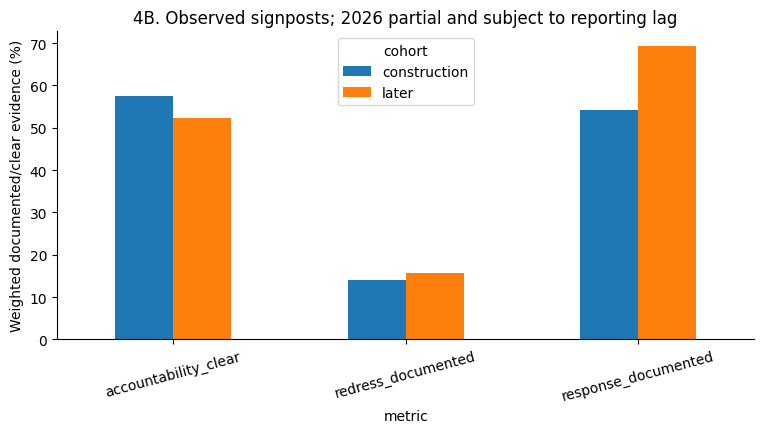

,scenario_id,Incident ID,judgment,reason,evidence_url,authorship
0,S1,1585,supports,Discord account reinstatement illustrates an i...,https://incidentdatabase.ai/cite/1585/,Codex_AI; conditional interpretation of archiv...
1,S1,1386,supports,The NotebookLM voice lawsuit illustrates an id...,https://incidentdatabase.ai/cite/1386/,Codex_AI; conditional interpretation of archiv...
2,S1,1361,challenges,The Waymo child-collision summary documents in...,https://incidentdatabase.ai/cite/1361/,Codex_AI; conditional interpretation of archiv...
3,S2,1412,supports,The Lilli breach summary identifies organizati...,https://incidentdatabase.ai/cite/1412/,Codex_AI; conditional interpretation of archiv...
4,S2,1707,supports,The Medicare portal incident identifies OpenAI...,https://incidentdatabase.ai/cite/1707/,Codex_AI; conditional interpretation of archiv...
5,S2,1585,challenges,Actual account reinstatement is a counterexamp...,https://incidentdatabase.ai/cite/1585/,Codex_AI; conditional interpretation of archiv...
6,S3,1693,unclear,"A regulator received a breach notification, bu...",https://incidentdatabase.ai/cite/1693/,Codex_AI; conditional interpretation of archiv...
7,S3,1493,challenges,Multiple-model imagery errors retain unclear a...,https://incidentdatabase.ai/cite/1493/,Codex_AI; conditional interpretation of archiv...
8,S3,1720,challenges,A restraining order and contract termination i...,https://incidentdatabase.ai/cite/1720/,Codex_AI; conditional interpretation of archiv...
9,S4,1406,supports,The collective wartime-fakes summary lacks spe...,https://incidentdatabase.ai/cite/1406/,Codex_AI; conditional interpretation of archiv...


,scenario_id,claims,evidence_cases,signposts,later_cases,challenging_cases
0,S1,2,2,2,3,1
1,S2,2,2,2,3,1
2,S3,1,1,2,3,2
3,S4,2,2,2,3,1


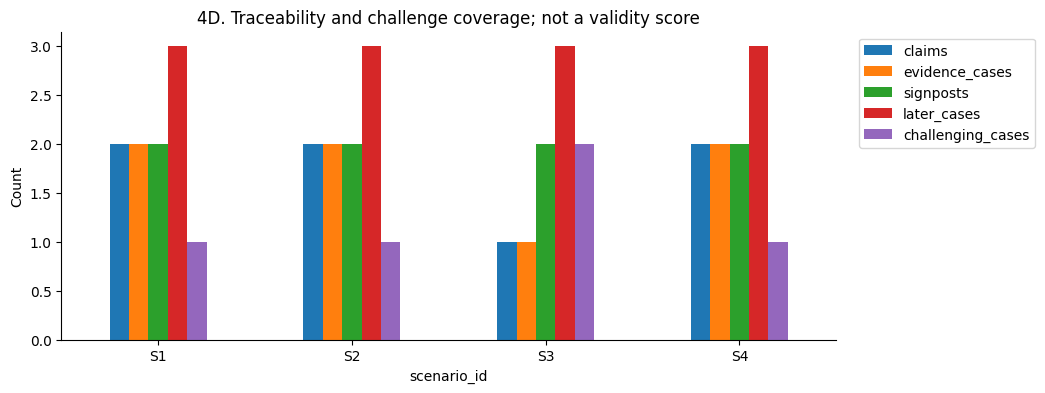

In [14]:
if scenario_data is not None:
    sc,cl,sp,ch=scenario_data
    ledger=sc.merge(cl.groupby('scenario_id').agg(evidence_claims=('claim_id','size'),distinct_construction_cases=('Incident ID','nunique')),on='scenario_id')
    save_table(ledger,'table_4A_scenario_evidence_ledger');save_table(cl,'scenario_claims');success('4A')
    metrics=[]
    definitions={'response_documented':('response','documented'),'redress_documented':('redress','documented'),'accountability_clear':('accountability_clarity','clear')}
    for cohort,g in coded.groupby('cohort'):
        for metric,(field,label) in definitions.items():
            metrics.append({'cohort':cohort,'metric':metric,'weighted_fraction':np.average(g[field].eq(label),weights=g.design_weight),'sample_n':len(g)})
    metrics=pd.DataFrame(metrics);sign_values=sp.merge(metrics,on='metric',how='left')
    sign_values['review_triggered']=np.where(sign_values.direction.eq('above'),sign_values.weighted_fraction.gt(sign_values.threshold),sign_values.weighted_fraction.lt(sign_values.threshold))
    save_table(sign_values,'figure_4B_values')
    threshold_rows=[]
    for metric in ['accountability_clear','redress_documented']:
        grid=[.60,.70,.80] if metric=='accountability_clear' else [.15,.25,.35]
        for threshold in grid:
            for row in metrics[metrics.metric.eq(metric)].itertuples():
                threshold_rows.append({'metric':metric,'cohort':row.cohort,'threshold':threshold,'weighted_fraction':row.weighted_fraction,'above':row.weighted_fraction>threshold,'below':row.weighted_fraction<threshold,'interpretation':'illustrative threshold sensitivity; not estimated or validated'})
    save_table(pd.DataFrame(threshold_rows),'signpost_threshold_sensitivity')
    p=metrics.pivot(index='metric',columns='cohort',values='weighted_fraction')
    ax=(100*p).plot.bar(figsize=(9,4),rot=15);ax.set(ylabel='Weighted documented/clear evidence (%)',title='4B. Observed signposts; 2026 partial and subject to reporting lag')
    save_figure(ax.figure,'figure_4B_observed_signposts');success('4B')
    save_table(ch,'table_4C_later_case_challenge_log');success('4C')
    trace=pd.DataFrame([{'scenario_id':sid,'claims':len(cl[cl.scenario_id.eq(sid)]),'evidence_cases':cl.loc[cl.scenario_id.eq(sid),'Incident ID'].nunique(),'signposts':len(sp[sp.scenario_id.eq(sid)]),'later_cases':len(ch[ch.scenario_id.eq(sid)]),'challenging_cases':int(ch.loc[ch.scenario_id.eq(sid),'judgment'].eq('challenges').sum())} for sid in sc.scenario_id])
    save_table(trace,'figure_4D_values')
    ax=trace.set_index('scenario_id')[['claims','evidence_cases','signposts','later_cases','challenging_cases']].plot.bar(figsize=(10,4),rot=0)
    ax.set(ylabel='Count',title='4D. Traceability and challenge coverage; not a validity score');ax.legend(bbox_to_anchor=(1.02,1),loc='upper left')
    save_figure(ax.figure,'figure_4D_traceability');success('4D')

## 15. Manifest, provenance and ZIP

Method step 10: include only files generated in this fresh run. Record missing analyses explicitly. All figures display inline and export PDF/PNG; every table and figure values export CSV. The notebook never fabricates results to reach sixteen exhibits.

In [15]:
expected=['1A','1B','1C','1D','2A','2B','2C','2D','3A','3B','3C','3D','4A','4B','4C','4D']
report=pd.DataFrame([{'exhibit':k,'status':status.get(k,'PENDING')} for k in expected]);save_table(report,'exhibit_status')
packages={p:importlib.metadata.version(p) for p in ['pandas','numpy','matplotlib','scikit-learn','openpyxl']}
provenance={'source_filename':source.name,'source_sha256':sha256,'seed':SEED,'bootstrap_replicates':BOOTSTRAPS,'python':platform.python_version(),'packages':packages,'counts':{'incidents':len(inc),'reports':len(rep),'entities':len(ent),'construction':len(construction),'later':len(later)},'review_file_hashes':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in REVIEW_DIR.glob('*.csv')} if REVIEW_DIR.exists() else {},'coding_provenance':'Shared AI-assisted draft label sets, reported team verification and adjudication; agreement is not independent-human reliability.','limitations':['Media-selected archive; not population incidence.','Weights address the designed review sample only.','Intervals omit media selection and coding uncertainty.','2026 is incomplete and classification lag is substantial.','Scenario traceability does not validate a forecast.']}
p=out/'provenance.json';p.write_text(json.dumps(provenance,indent=2));manifest.append(p)
manifest=list(dict.fromkeys(p for p in manifest if p.name != 'output_manifest.csv'))
files=pd.DataFrame([{'filename':p.name,'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in manifest]);save_table(files,'output_manifest')
archive=base/f'project11_final_results_{run_id}.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in manifest:z.write(path,arcname=path.name)
print('Results ZIP:',archive)
print('Generated exhibits:',sum(v=='GENERATED' for v in status.values()),'/16. Pending exhibits require genuine human evidence.')

,exhibit,status
0,1A,GENERATED
1,1B,GENERATED
2,1C,GENERATED
3,1D,GENERATED
4,2A,GENERATED
5,2B,GENERATED
6,2C,GENERATED
7,2D,GENERATED
8,3A,GENERATED
9,3B,GENERATED


,filename,bytes,sha256
0,data_audit.csv,230,6e67a0e2a7831ca2e4fd40d636d655bd814a42e19518f7...
1,field_missingness.csv,2200,7d06e6735e124716fe2e7b48a0742dd009257a6959691f...
2,sampling_frame_selected.csv,135755,438604385b5e68f4acf13c75a15210beb575f65fcf3f97...
3,coding_codebook.csv,804,9f06949f160bef0cb76827fba75333136e8971801f29ac...
4,independent_codes_TEMPLATE.csv,4579,b31e6152118dbdd7deb978e795d8f982025683185c8e80...
5,adjudicated_codes_TEMPLATE.csv,2191,de49a0b1ca6ca8567d474dd7f81f0f86322354b9f86ea6...
6,table_1A_role_risk_screen.csv,1209,ffafd904158954f79b9234adc1b77eb5d66f60f3fc983c...
7,figure_1B_values.csv,138,5a05532ef7f178f8f72dbd4ae13ce3faba15a616501d40...
8,figure_1B_affected_party_coverage.pdf,13140,a11407032d0c30dfb00a2edaa645e32ef5999e731ba4cc...
9,figure_1B_affected_party_coverage.png,95399,2ea28dadc925a8c164ee3061d02a5088e619e3c47b57b3...


Results ZIP: /kaggle/working/project11_final_results_7e50356660.zip
Generated exhibits: 16 /16. Pending exhibits require genuine human evidence.
